# Homework 4

## Maxwell Bederman

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    auc,
    confusion_matrix,
    get_scorer,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.utils import resample
from statsmodels.tools.sm_exceptions import PerfectSeparationWarning
from tqdm.auto import tqdm

/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-4/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Time Series Classification Part 1

### b)

In [2]:
def load_arems(data_root="../data/AReM"):
    columns = [
        "time",
        "avg_rss12",
        "var_rss12",
        "avg_rss13",
        "var_rss13",
        "avg_rss23",
        "var_rss23",
    ]

    root = Path(data_root)
    train_dfs, test_dfs = [], []

    for action_dir in sorted(path for path in root.iterdir() if path.is_dir()):
        action = action_dir.name
        test_ids = {1, 2} if action in {"bending1", "bending2"} else {1, 2, 3}

        csv_files = sorted(
            action_dir.glob("dataset*.csv"),
            key=lambda path: int(path.stem.removeprefix("dataset")),
        )

        for path in csv_files:
            dataset_id = int(path.stem.removeprefix("dataset"))

            df = pd.read_csv(
                path,
                skiprows=5,
                header=None,
                names=columns,
                sep=r"\s*,\s*|\s+",
                engine="python",
                usecols=range(7),
            )

            # Keep provenance visible in every individual recording.
            df.insert(0, "action", action)
            df.insert(1, "dataset_id", dataset_id)

            if dataset_id in test_ids:
                test_dfs.append(df)
            else:
                train_dfs.append(df)

    return train_dfs, test_dfs

In [3]:
train_dfs, test_dfs = load_arems()

### c) Feature Extraction

#### i)

Max, min, mean, median, std dev, quartiles, trend, breaking up these features over smaller timeframes within the time series, seasonality, range

https://medium.com/@adnan.mazraeh1993/time-series-features-from-basics-to-super-advanced-3589944f6a98

#### ii)



In [4]:
def extract_features(dfs, l=1):
    if not isinstance(l, int) or l < 1:
        raise ValueError("l must be a positive integer.")

    time_series_columns = [
        "avg_rss12",
        "var_rss12",
        "avg_rss13",
        "var_rss13",
        "avg_rss23",
        "var_rss23",
    ]

    rows = []

    for df in dfs:
        if l > len(df):
            raise ValueError(
                f"l={l} is larger than the {len(df)} time points in an instance."
            )

        action = df["action"].iat[0]

        row = {
            "action": action,
            "dataset_id": df["dataset_id"].iat[0],
            "label": int(action in {"bending1", "bending2"}),
        }

        for series_number, column in enumerate(time_series_columns, start=1):
            segments = np.array_split(df[column].to_numpy(), l)

            for segment_number, segment in enumerate(segments, start=1):
                segment = pd.Series(segment)

                # Preserve original feature names when l=1.
                suffix = (
                    str(series_number)
                    if l == 1
                    else f"{series_number}_{segment_number}"
                )

                row[f"min_{suffix}"] = segment.min()
                row[f"max_{suffix}"] = segment.max()
                row[f"mean_{suffix}"] = segment.mean()
                row[f"median_{suffix}"] = segment.median()
                row[f"std_{suffix}"] = segment.std()
                row[f"q1_{suffix}"] = segment.quantile(0.25)
                row[f"q3_{suffix}"] = segment.quantile(0.75)

        rows.append(row)

    return pd.DataFrame(rows)

In [5]:
train_df, test_df = extract_features(train_dfs), extract_features(test_dfs)
total_df = pd.concat([train_df, test_df], axis=0, ignore_index=True)
total_df

,action,dataset_id,label,min_1,max_1,mean_1,median_1,std_1,q1_1,q3_1,...,std_5,q1_5,q3_5,min_6,max_6,mean_6,median_6,std_6,q1_6,q3_6
0,bending1,3,1,35.00,47.40,43.954500,44.330,1.558835,43.00,45.0000,...,1.999604,35.3625,36.500,0.0,1.79,0.493292,0.430,0.513506,0.000,0.940
1,bending1,4,1,33.00,47.75,42.179812,43.500,3.670666,39.15,45.0000,...,3.849448,30.4575,36.330,0.0,2.18,0.613521,0.500,0.524317,0.000,1.000
2,bending1,5,1,33.00,45.75,41.678063,41.750,2.243490,41.33,42.7500,...,2.411026,28.4575,31.250,0.0,1.79,0.383292,0.430,0.389164,0.000,0.500
3,bending1,6,1,37.00,48.00,43.454958,43.250,1.386098,42.50,45.0000,...,2.488862,22.2500,24.000,0.0,5.26,0.679646,0.500,0.622534,0.430,0.870
4,bending1,7,1,36.25,48.00,43.969125,44.500,1.618364,43.31,44.6700,...,3.318301,20.5000,23.750,0.0,2.96,0.555312,0.490,0.487826,0.000,0.830
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,standing,2,0,35.50,46.25,43.174938,43.670,1.989052,42.50,44.5000,...,2.983976,12.7500,16.500,0.0,5.72,0.911979,0.830,0.666161,0.470,1.220
84,standing,3,0,32.75,47.00,42.760562,44.500,3.398919,41.33,45.3725,...,4.296574,13.0000,18.565,0.0,5.73,0.842271,0.710,0.722165,0.430,1.090
85,walking,1,0,19.33,43.50,34.227771,35.500,4.889576,30.50,37.7500,...,3.092094,14.7500,18.670,0.0,9.74,3.394125,3.100,1.792090,2.105,4.425
86,walking,2,0,12.50,45.00,33.509729,34.125,4.850923,30.50,36.7500,...,3.133564,14.6275,18.750,0.0,8.96,3.378479,3.085,1.787360,2.060,4.440


In [6]:
test_df

,action,dataset_id,label,min_1,max_1,mean_1,median_1,std_1,q1_1,q3_1,...,std_5,q1_5,q3_5,min_6,max_6,mean_6,median_6,std_6,q1_6,q3_6
0,bending1,1,1,37.25,45.00,40.624792,40.500,1.476967,39.2500,42.0000,...,2.188449,33.0000,36.0000,0.0,1.92,0.570583,0.430,0.582915,0.0000,1.300
1,bending1,2,1,38.00,45.67,42.812812,42.500,1.435550,42.0000,43.6700,...,1.995255,32.0000,34.5000,0.0,3.11,0.571083,0.430,0.601010,0.0000,1.300
2,bending2,1,1,12.75,51.00,24.562958,24.250,3.737514,23.1875,26.5000,...,3.693786,20.5000,27.0000,0.0,4.97,0.700188,0.500,0.693720,0.4300,0.870
3,bending2,2,1,0.00,42.75,27.464604,28.000,3.583582,25.5000,30.0000,...,5.053642,15.0000,20.7500,0.0,6.76,1.122125,0.830,1.012342,0.4700,1.300
4,cycling,1,0,24.25,45.00,37.177042,36.250,3.581301,34.5000,40.2500,...,2.890347,17.9500,21.7500,0.0,9.34,2.921729,2.500,1.852600,1.5000,3.900
5,cycling,2,0,28.75,44.75,37.561187,36.875,3.226507,35.2500,40.2500,...,2.727377,18.0000,21.5000,0.0,9.62,2.765896,2.450,1.769203,1.4100,3.770
6,cycling,3,0,22.00,44.67,37.058708,36.000,3.710180,34.5000,40.0625,...,3.537144,16.0000,21.0000,0.0,8.55,2.983750,2.570,1.815730,1.5000,4.150
7,lying,1,0,23.50,30.00,27.716375,27.500,1.442253,27.0000,29.0000,...,4.074511,5.5000,10.7500,0.0,4.50,0.734271,0.710,0.613688,0.4300,1.000
8,lying,2,0,24.75,48.33,44.182937,48.000,7.495615,48.0000,48.0000,...,3.274539,2.0000,5.5425,0.0,3.91,0.692771,0.500,0.675781,0.3225,0.940
9,lying,3,0,48.00,48.25,48.004167,48.000,0.032038,48.0000,48.0000,...,3.268502,4.6700,10.0000,0.0,2.50,0.641229,0.500,0.388372,0.4600,0.830


#### iii)

In [7]:
def feature_std_summary(df, n_bootstrap=1_000, random_state=None):
    excluded_columns = {"action", "dataset_id", "label"}

    feature_columns = [
        column
        for column in df.columns
        if column not in excluded_columns and pd.api.types.is_numeric_dtype(df[column])
    ]

    feature_df = df[feature_columns]
    n_instances = len(feature_df)

    if n_instances < 2:
        raise ValueError("At least two instances are required.")

    rng = np.random.default_rng(random_state)
    bootstrap_stds = []

    for _ in range(n_bootstrap):
        bootstrap_sample = resample(
            feature_df,
            replace=True,
            n_samples=n_instances,
            random_state=int(rng.integers(0, 2**32 - 1)),
        )
        bootstrap_stds.append(bootstrap_sample.std(ddof=1))

    bootstrap_stds = pd.DataFrame(bootstrap_stds)

    return pd.DataFrame(
        {
            "feature": feature_columns,
            "sample_std": feature_df.std(ddof=1).values,
            "ci_90_lower": bootstrap_stds.quantile(0.05).values,
            "ci_90_upper": bootstrap_stds.quantile(0.95).values,
        }
    )

In [8]:
feature_std_summary(total_df, random_state=552)

,feature,sample_std,ci_90_lower,ci_90_upper
0,min_1,9.569975,8.286940,10.667207
1,max_1,4.394362,3.334811,5.300569
2,mean_1,5.335718,4.708396,5.894766
3,median_1,5.440054,4.786177,5.990716
4,std_1,1.772153,1.577777,1.935934
5,q1_1,6.153590,5.576027,6.645973
6,q3_1,5.138925,4.337904,5.827670
7,min_2,0.000000,0.000000,0.000000
8,max_2,5.062729,4.643719,5.410571
9,mean_2,1.574164,1.411240,1.713488


#### iv)

I am choosing min, max and std dev. I think min and max are good choices because for body movements I think that the extremes make sense as an indicator of the type of movement. Also std dev because the overall variation of the movement should also be indicative of the type of movement it is.

## 2.  Time Series Classification Part 2

### a) Binary Classification using Logistic Regression

#### i)

In [9]:
def plot_feature_pairs(df, class_col):
    feature_cols = df.drop(columns=class_col).select_dtypes(include="number").columns
    classes = df[class_col].unique()

    n_features = len(feature_cols)

    fig, axes = plt.subplots(n_features, n_features, figsize=(10, 10))

    for row, y_col in enumerate(feature_cols):
        for col, x_col in enumerate(feature_cols):
            ax = axes[row, col]

            if row == col:
                ax.text(
                    0.5,
                    0.5,
                    x_col,
                    ha="center",
                    va="center",
                    fontsize=8,
                    fontweight="bold",
                    transform=ax.transAxes,
                )

                ax.set_xticks([])
                ax.set_yticks([])

            else:
                for class_name in classes:
                    subset = df[df[class_col] == class_name]

                    ax.scatter(
                        subset[x_col], subset[y_col], label=class_name, alpha=0.7, s=8
                    )

                ax.tick_params(labelsize=6)

            if row == n_features - 1:
                ax.set_xlabel(x_col, fontsize=7)

            if col == 0:
                ax.set_ylabel(y_col, fontsize=7)

    handles, labels = axes[0, 1].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        title=class_col,
        loc="upper right",
        fontsize=7,
        title_fontsize=8,
    )

    plt.tight_layout()
    plt.show()

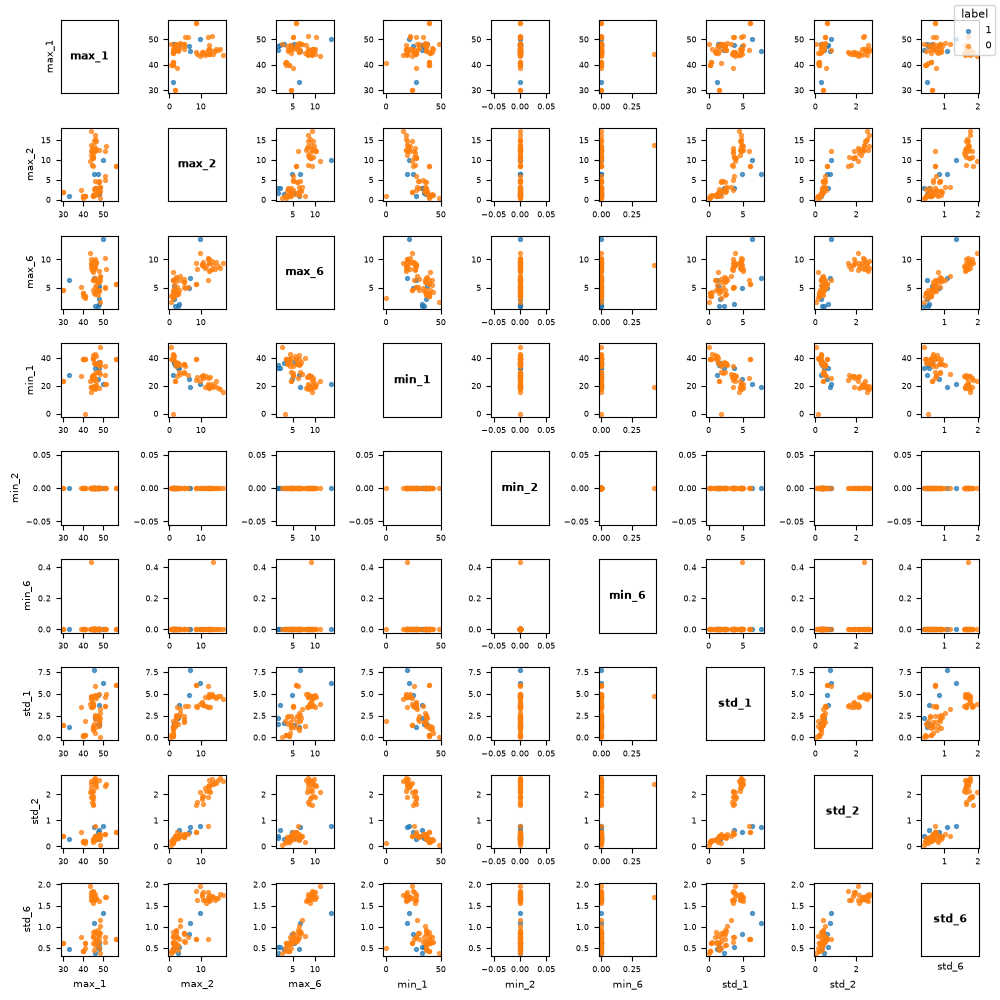

In [10]:
selected_features = [
    f"{stat}_{series}" for stat in ("max", "min", "std") for series in (1, 2, 6)
]
selected_features.append("label")
plot_feature_pairs(train_df[selected_features], class_col="label")

#### ii)

In [11]:
train_df = extract_features(train_dfs, l=2)
train_df

,action,dataset_id,label,min_1_1,max_1_1,mean_1_1,median_1_1,std_1_1,q1_1_1,q3_1_1,...,std_6_1,q1_6_1,q3_6_1,min_6_2,max_6_2,mean_6_2,median_6_2,std_6_2,q1_6_2,q3_6_2
0,bending1,3,1,36.50,46.50,44.057167,44.500,1.556971,43.2500,45.0000,...,0.526656,0.00,1.0000,0.00,1.50,0.388333,0.000,0.478528,0.0000,0.7100
1,bending1,4,1,33.75,47.75,43.278875,45.000,3.473355,42.0000,45.2500,...,0.554542,0.00,1.2200,0.00,2.18,0.586083,0.470,0.491873,0.0000,0.8700
2,bending1,5,1,33.00,45.75,41.621208,42.330,3.118644,39.6525,44.2500,...,0.411200,0.00,0.7100,0.00,1.50,0.347500,0.430,0.363144,0.0000,0.5000
3,bending1,6,1,39.00,48.00,44.117042,45.000,1.359836,43.5000,45.0000,...,0.718016,0.43,1.1200,0.00,4.06,0.543875,0.500,0.473445,0.4300,0.7100
4,bending1,7,1,36.67,45.00,43.486208,43.710,1.281976,42.3300,44.5000,...,0.486847,0.00,0.8300,0.00,2.96,0.585750,0.500,0.487918,0.4225,0.8300
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64,walking,11,0,19.50,45.00,33.334500,34.000,4.874433,29.9375,36.8125,...,1.637310,2.06,4.2450,0.43,8.32,3.290292,3.155,1.646023,2.0500,4.4525
65,walking,12,0,20.33,44.50,34.036750,34.415,4.872880,30.7500,37.7500,...,1.703098,2.28,4.7900,0.00,9.67,3.321417,3.155,1.758379,2.0500,4.3950
66,walking,13,0,19.50,43.33,34.033875,35.000,4.758757,30.9375,37.5000,...,1.619767,2.15,4.1500,0.00,8.64,3.432208,3.255,1.691050,2.1600,4.5125
67,walking,14,0,24.33,44.00,34.920792,35.330,4.272282,32.2500,37.8125,...,1.781928,2.16,4.5850,0.00,9.51,3.418667,3.350,1.598536,2.1700,4.4525


/var/folders/wz/dvph41sd38x6rxm2cyvp85v40000gn/T/ipykernel_60104/3814528547.py:55: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


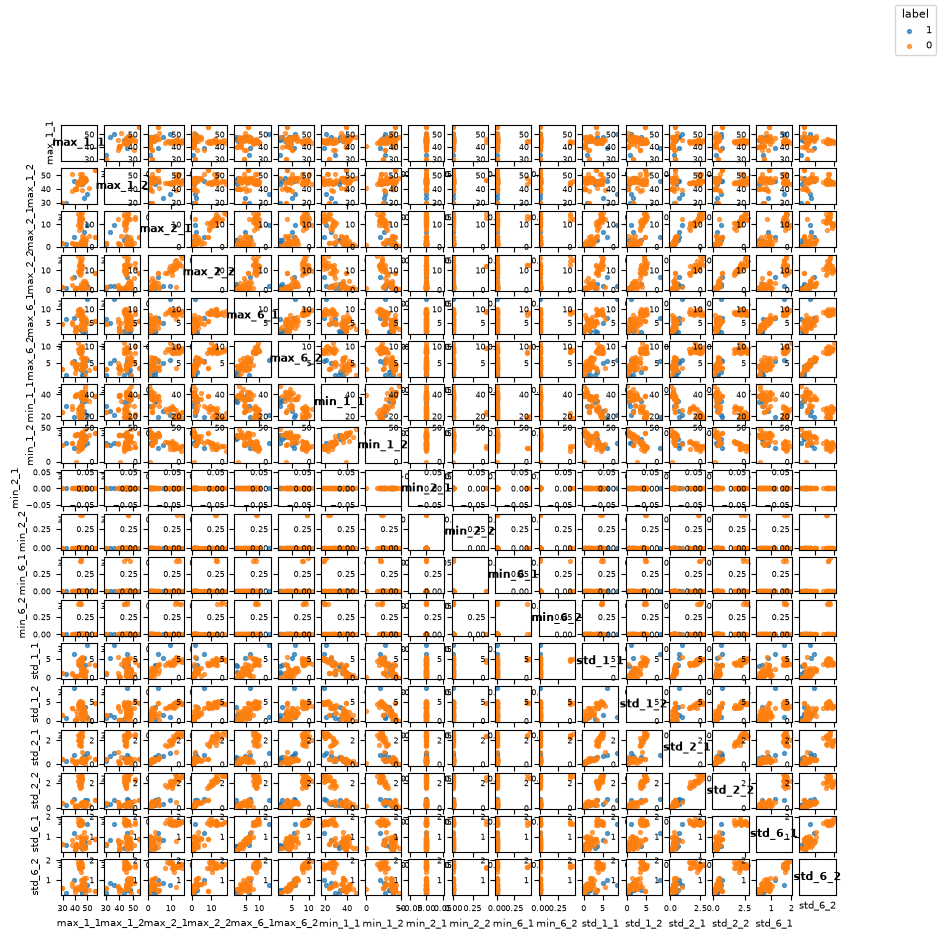

In [12]:
selected_features = [
    f"{stat}_{series}_{segment}"
    for stat in ("max", "min", "std")
    for series in (1, 2, 6)
    for segment in (1, 2)
]
selected_features.append("label")
plot_feature_pairs(train_df[selected_features], class_col="label")

The std vs min graphs still appear like theres no relationship but I think thats becayse of one extreme. You can see more variation in where the bending labels are relative to the features. 

#### iii)

In [13]:
def candidate_feature_names(l, stats):
    return [
        f"{stat}_{series}" if l == 1 else f"{stat}_{series}_{segment}"
        for stat in stats
        for series in range(1, 7)
        for segment in range(1, l + 1)
    ]


def prepare_xy(dfs, l, stats):
    feature_df = extract_features(dfs, l=l)
    candidate_features = candidate_feature_names(l, stats)

    X = feature_df[candidate_features]
    y = feature_df["label"].to_numpy()

    return feature_df, X, y


def make_logistic_model(random_state=552, l1=False, lambda_=None):
    if l1:
        return LogisticRegression(
            solver="liblinear",
            l1_ratio=1,
            C=1 / lambda_,
            max_iter=10_000,
            random_state=random_state,
        )

    return LogisticRegression(
        solver="liblinear",
        C=1e6,
        max_iter=10_000,
        random_state=random_state,
    )


def case_control_sample(X, y, random_state):
    cases = np.flatnonzero(y == 1)
    controls = np.flatnonzero(y == 0)

    rng = np.random.default_rng(random_state)
    sampled_controls = rng.choice(
        controls,
        size=len(cases),
        replace=False,
    )
    sampled_indices = np.concatenate([cases, sampled_controls])
    rng.shuffle(sampled_indices)

    return X[sampled_indices], y[sampled_indices]


def adjust_case_control_intercept(classifier, original_y, sampled_y):
    original_rate = original_y.mean()
    sampled_rate = sampled_y.mean()

    classifier.intercept_ += np.log(original_rate / (1 - original_rate)) - np.log(
        sampled_rate / (1 - sampled_rate)
    )

    return classifier


def tune_regression(
    dfs,
    l_values=range(1, 21),
    stats=("max", "min", "std"),
    n_splits=5,
    scoring="accuracy",
    random_state=552,
    case_control=False,
    l1=False,
    lambdas=None,
):
    results = []
    scorer = get_scorer(scoring)

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state,
    )

    folds = None
    if l1 and lambdas is None:
        raise ValueError("Pass lambdas when l1=True.")

    lambda_values = lambdas if l1 else (None,)

    for l in tqdm(l_values, desc="Tuning l", unit="l"):
        _, X, y = prepare_xy(dfs, l=l, stats=stats)

        if folds is None:
            folds = list(cv.split(X, y))

        n_features = X.shape[1]
        if l1:
            fold_scores = {lambda_: np.empty(n_splits) for lambda_ in lambda_values}
        else:
            fold_scores = {
                lambda_: np.empty((n_splits, n_features)) for lambda_ in lambda_values
            }

        for fold_number, (train_idx, validation_idx) in enumerate(folds):
            X_train = X.iloc[train_idx].to_numpy()
            X_validation = X.iloc[validation_idx].to_numpy()
            y_train = y[train_idx]
            y_validation = y[validation_idx]

            if case_control:
                X_fit, y_fit = case_control_sample(
                    X_train,
                    y_train,
                    random_state + fold_number,
                )
            else:
                X_fit, y_fit = X_train, y_train

            scaler = StandardScaler()
            X_fit_model = scaler.fit_transform(X_fit)
            X_validation_model = scaler.transform(X_validation)

            for lambda_ in lambda_values:
                if l1:
                    classifier = make_logistic_model(
                        random_state,
                        l1=True,
                        lambda_=lambda_,
                    )
                    classifier.fit(X_fit_model, y_fit)

                    if case_control:
                        classifier = adjust_case_control_intercept(
                            classifier,
                            y_train,
                            y_fit,
                        )

                    fold_scores[lambda_][fold_number] = scorer(
                        classifier,
                        X_validation_model,
                        y_validation,
                    )
                else:
                    rfe = RFE(
                        estimator=make_logistic_model(random_state),
                        n_features_to_select=1,
                        step=1,
                    )
                    rfe.fit(X_fit_model, y_fit)

                    for p in range(1, n_features + 1):
                        selected_mask = rfe.ranking_ <= p
                        classifier = make_logistic_model(random_state)
                        classifier.fit(X_fit_model[:, selected_mask], y_fit)

                        if case_control:
                            classifier = adjust_case_control_intercept(
                                classifier,
                                y_train,
                                y_fit,
                            )

                        fold_scores[lambda_][fold_number, p - 1] = scorer(
                            classifier,
                            X_validation_model[:, selected_mask],
                            y_validation,
                        )

        for lambda_ in lambda_values:
            if l1:
                scores = fold_scores[lambda_]
                results.append(
                    {
                        "l": l,
                        "l1": True,
                        "lambda": lambda_,
                        "mean_cv_score": scores.mean(),
                        "std_cv_score": scores.std(),
                    }
                )
            else:
                for p in range(1, n_features + 1):
                    scores = fold_scores[lambda_][:, p - 1]

                    results.append(
                        {
                            "l": l,
                            "p": p,
                            "l1": False,
                            "lambda": lambda_,
                            "mean_cv_score": scores.mean(),
                            "std_cv_score": scores.std(),
                        }
                    )

    all_results = pd.DataFrame(results)

    best_by_l = (
        all_results.loc[all_results.groupby("l")["mean_cv_score"].idxmax()]
        .sort_values("l")
        .reset_index(drop=True)
    )

    return all_results, best_by_l


In [14]:
stats = ("max", "min", "std")

all_cv_results, best_by_l = tune_regression(
    train_dfs,
    stats=stats,
)

best_row = best_by_l.sort_values(
    ["mean_cv_score", "l"],
    ascending=[False, True],
).iloc[0]

best_l = int(best_row["l"])
best_p = int(best_row["p"])

print(f"Binary Logistic Regression with RFE — Best (l, p) = ({best_l}, {best_p})")

Tuning l:   0%|          | 0/20 [00:00<?, ?l/s]

Tuning l: 100%|██████████| 20/20 [00:59<00:00,  2.99s/l]

Binary Logistic Regression with RFE — Best (l, p) = (3, 1)


The incorrect way to do the cross validation is to perform a grid search on all possible values of (l, p). This will take too long and performs redundant work. Instead, we can greedily perform recursive feature elimination for each value of l and report the validation accuracy for each fold, then just take the average for each p across all the folds. 

#### iv)

In [15]:
def get_selected_data(fitted_model, dfs):
    feature_df, X, y = prepare_xy(
        dfs,
        l=fitted_model["l"],
        stats=fitted_model["stats"],
    )

    X_model = fitted_model["scaler"].transform(X.to_numpy())

    if fitted_model["l1"]:
        X_selected = X_model
    else:
        X_selected = fitted_model["rfe"].transform(X_model)

    selected_feature_names = np.array(
        candidate_feature_names(
            fitted_model["l"],
            fitted_model["stats"],
        )
    )

    if not fitted_model["l1"]:
        selected_feature_names = selected_feature_names[fitted_model["rfe"].support_]

    return feature_df, X_selected, y, selected_feature_names


def evaluate_final_model(fitted_model, dfs, model_name=None):
    feature_df, X_selected, y, _ = get_selected_data(fitted_model, dfs)

    classifier = fitted_model["classifier"]
    predictions = classifier.predict(X_selected)
    probabilities = classifier.predict_proba(X_selected)[:, 1]

    cm = confusion_matrix(y, predictions)
    fpr, tpr, thresholds = roc_curve(y, probabilities)
    auc_score = roc_auc_score(y, probabilities)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["other", "bending"],
    ).plot(ax=axes[0])

    title_prefix = f"{model_name} — " if model_name else ""
    axes[0].set_title(f"{title_prefix}Confusion Matrix")

    axes[1].plot(fpr, tpr, label=f"AUC = {auc_score:.3f}")
    axes[1].plot([0, 1], [0, 1], linestyle="--")
    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate")
    axes[1].set_title(f"{title_prefix}ROC Curve")
    axes[1].legend()

    plt.show()

    predictions_df = feature_df[["action", "dataset_id", "label"]].copy()

    predictions_df["prediction"] = predictions
    predictions_df["bending_probability"] = probabilities

    return {
        "confusion_matrix": cm,
        "auc": auc_score,
        "fpr": fpr,
        "tpr": tpr,
        "thresholds": thresholds,
        "predictions": predictions_df,
    }


def model_parameters_and_pvalues(fitted_model, train_dfs):
    _, X_selected, y, selected_feature_names = get_selected_data(
        fitted_model,
        train_dfs,
    )

    if fitted_model["l1"]:
        X_selected = X_selected[:, fitted_model["selected_mask"]]
        selected_feature_names = selected_feature_names[fitted_model["selected_mask"]]

    if fitted_model["case_control"]:
        X_selected, y = case_control_sample(
            X_selected,
            y,
            fitted_model["random_state"],
        )

    X_statsmodels = pd.DataFrame(
        X_selected,
        columns=selected_feature_names,
    )

    X_statsmodels = sm.add_constant(X_statsmodels)

    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always", PerfectSeparationWarning)
        result = sm.Logit(y, X_statsmodels).fit(disp=False)

    separation_detected = any(
        issubclass(warning.category, PerfectSeparationWarning)
        for warning in caught_warnings
    )

    summary = pd.DataFrame(
        {
            "parameter": result.params.index,
            "coefficient": result.params.values,
            "p_value": result.pvalues.values,
        }
    )
    summary["p_values_reliable"] = not separation_detected

    return summary


def fit_final_model(
    dfs,
    l,
    p=None,
    stats=("max", "min", "std"),
    random_state=552,
    case_control=False,
    l1=False,
    lambda_=None,
):
    _, X_train, y_train = prepare_xy(dfs, l=l, stats=stats)

    if case_control:
        X_fit, y_fit = case_control_sample(
            X_train.to_numpy(),
            y_train,
            random_state,
        )
    else:
        X_fit = X_train.to_numpy()
        y_fit = y_train

    scaler = StandardScaler()
    X_fit_model = scaler.fit_transform(X_fit)

    if l1:
        rfe = None
        classifier = make_logistic_model(
            random_state,
            l1=True,
            lambda_=lambda_,
        )
        classifier.fit(X_fit_model, y_fit)
        selected_mask = classifier.coef_.ravel() != 0
    else:
        rfe = RFE(
            estimator=make_logistic_model(random_state),
            n_features_to_select=p,
            step=1,
        )
        X_train_selected = rfe.fit_transform(X_fit_model, y_fit)
        classifier = make_logistic_model(random_state)
        classifier.fit(X_train_selected, y_fit)
        selected_mask = rfe.support_

    if case_control:
        classifier = adjust_case_control_intercept(
            classifier,
            y_train,
            y_fit,
        )

    fitted_model = {
        "l": l,
        "stats": stats,
        "random_state": random_state,
        "case_control": case_control,
        "l1": l1,
        "lambda": lambda_,
        "selected_mask": selected_mask,
        "selected_features": X_train.columns[selected_mask].tolist(),
        "scaler": scaler,
        "rfe": rfe,
        "classifier": classifier,
    }

    if not l1:
        fitted_model["p"] = p

    return fitted_model

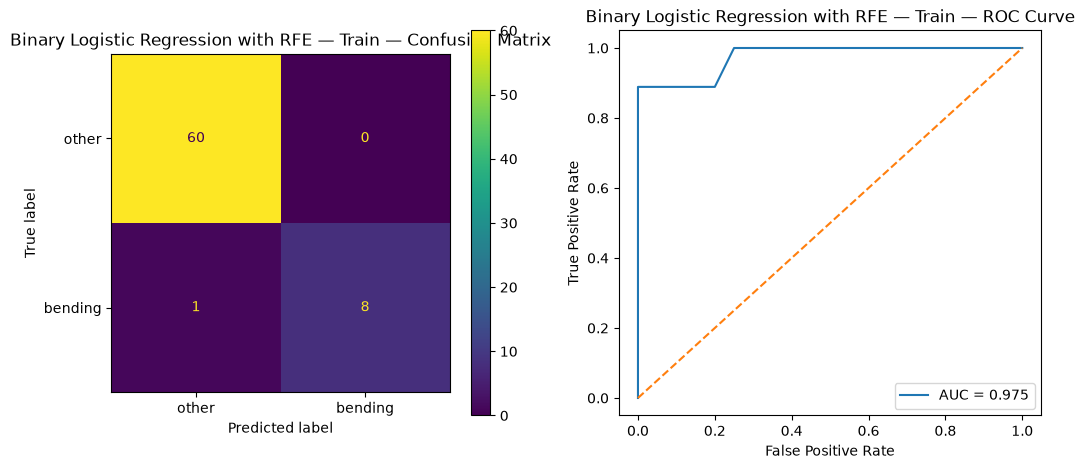

Binary Logistic Regression with RFE — Train AUC: 0.975


,parameter,coefficient,p_value,p_values_reliable
0,const,-4.645963,0.000713,True
1,max_5_1,4.586204,0.005198,True


In [16]:
fitted_model = fit_final_model(
    train_dfs,
    l=best_l,
    p=best_p,
    stats=stats,
)

model_name = "Binary Logistic Regression with RFE"

train_results = evaluate_final_model(
    fitted_model,
    train_dfs,
    model_name=f"{model_name} — Train",
)
parameter_table = model_parameters_and_pvalues(
    fitted_model,
    train_dfs,
)

print(f"{model_name} — Train AUC:", train_results["auc"])

parameter_table

#### v)

In [17]:
def predict_final_model(fitted_model, dfs):
    feature_df, X, y = prepare_xy(
        dfs,
        l=fitted_model["l"],
        stats=fitted_model["stats"],
    )

    X_model = fitted_model["scaler"].transform(X.to_numpy())

    if fitted_model["l1"]:
        X_selected = X_model
    else:
        X_selected = fitted_model["rfe"].transform(X_model)

    predictions = fitted_model["classifier"].predict(X_selected)
    probabilities = fitted_model["classifier"].predict_proba(X_selected)[:, 1]

    results = feature_df[["action", "dataset_id", "label"]].copy()

    results["prediction"] = predictions
    results["bending_probability"] = probabilities

    accuracy = (predictions == y).mean()

    return results, accuracy

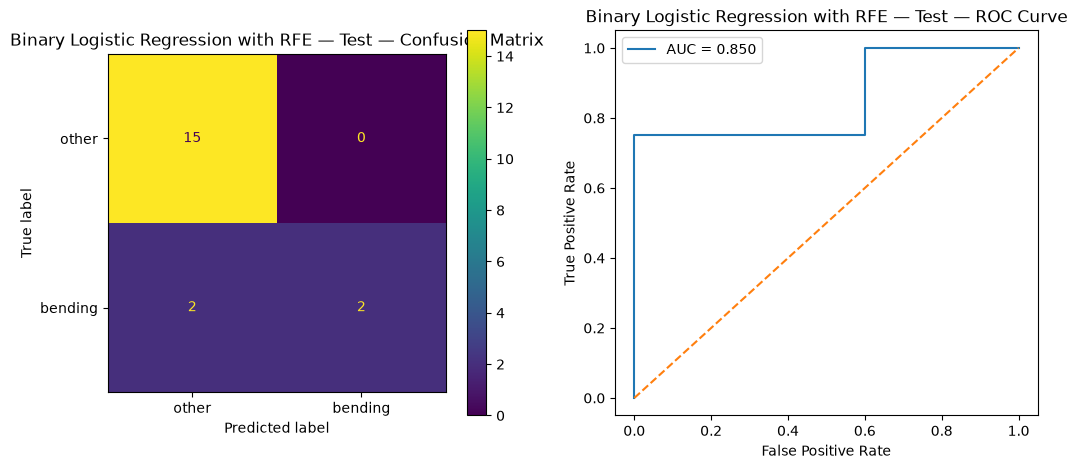

Binary Logistic Regression with RFE — Test accuracy: 0.8947368421052632


In [18]:
test_predictions, test_accuracy = predict_final_model(
    fitted_model,
    test_dfs,
)

test_results = evaluate_final_model(
    fitted_model,
    test_dfs,
    model_name=f"{model_name} — Test",
)

print(f"{model_name} — Test accuracy:", test_accuracy)

The test accuracy is pretty high but still lower than the train cv accuracy. Our model performs much worse on the positive class of the test set though at 50%.

#### vi)

I think because I standardized the data, the model we chose had data that wasn't perfectly separable so the p-values of the features are reliable.

#### vii)

There is class imbalance because there are way less positives in the test set relative to even the ratio of postives to negatives in the train set.

In [19]:
stats = ("max", "min", "std")

all_cv_results, best_by_l = tune_regression(train_dfs, stats=stats, case_control=True)

best_row = best_by_l.sort_values(
    ["mean_cv_score", "l", "p"],
    ascending=[False, True, True],
).iloc[0]

best_l = int(best_row["l"])
best_p = int(best_row["p"])

print(
    f"Case-Control Binary Logistic Regression with RFE — Best (l, p) = ({best_l}, {best_p})"
)

Tuning l: 100%|██████████| 20/20 [00:40<00:00,  2.02s/l]

Case-Control Binary Logistic Regression with RFE — Best (l, p) = (2, 3)


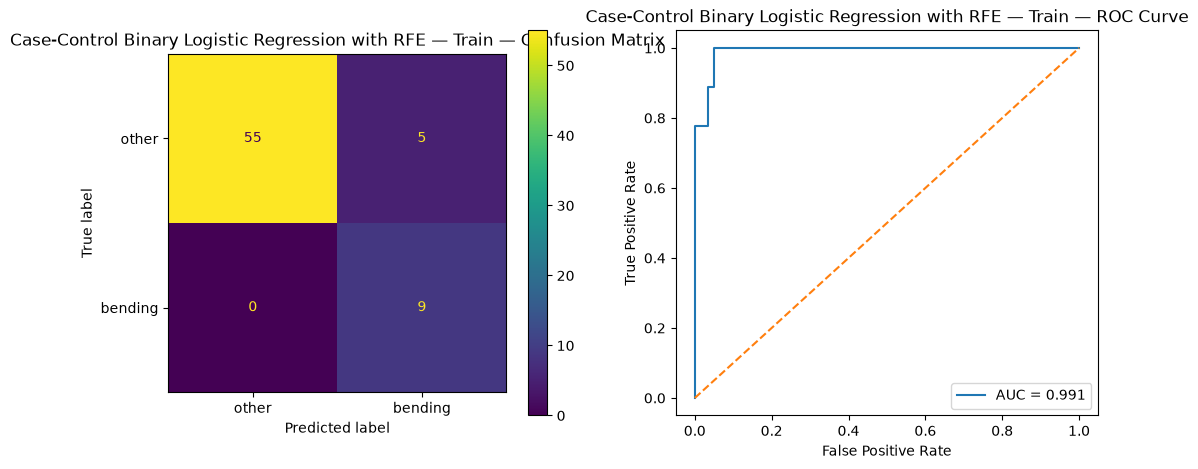

Case-Control Binary Logistic Regression with RFE — Train AUC: 0.9907407407407408


,parameter,coefficient,p_value,p_values_reliable
0,const,-48.890513,NaN,False
1,max_5_1,33.584829,NaN,False
2,std_3_1,31.502995,NaN,False
3,std_6_2,-78.956860,NaN,False


In [20]:
fitted_model = fit_final_model(
    train_dfs, l=best_l, p=best_p, stats=stats, case_control=True
)

model_name = "Case-Control Binary Logistic Regression with RFE"

train_results = evaluate_final_model(
    fitted_model,
    train_dfs,
    model_name=f"{model_name} — Train",
)
parameter_table = model_parameters_and_pvalues(
    fitted_model,
    train_dfs,
)

print(f"{model_name} — Train AUC:", train_results["auc"])

parameter_table

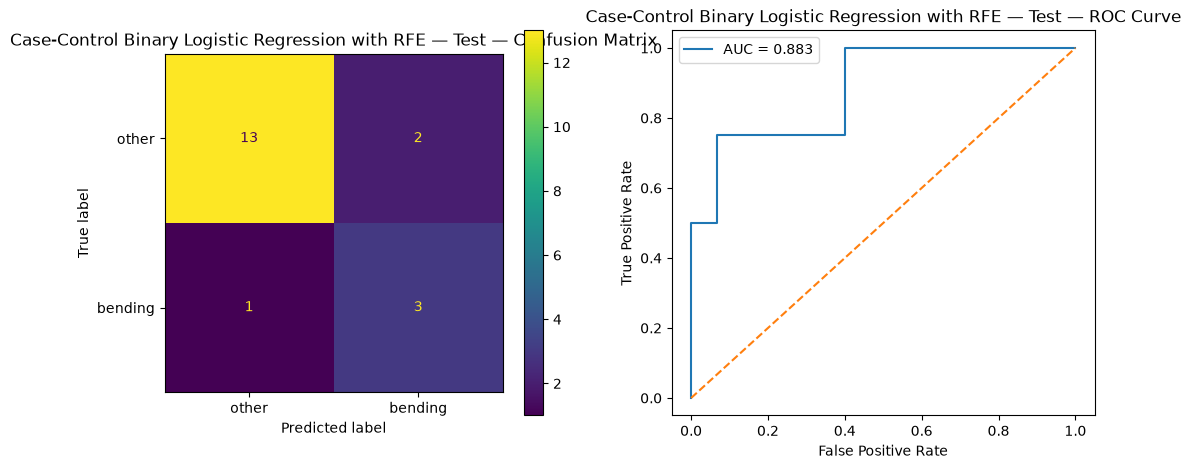

Case-Control Binary Logistic Regression with RFE — Test accuracy: 0.8421052631578947


In [21]:
test_predictions, test_accuracy = predict_final_model(
    fitted_model,
    test_dfs,
)

test_results = evaluate_final_model(
    fitted_model,
    test_dfs,
    model_name=f"{model_name} — Test",
)

print(f"{model_name} — Test accuracy:", test_accuracy)

### b)

#### i)

In [22]:
stats = ("max", "min", "std")
l1 = True
lambdas = tuple(10.0**exponent for exponent in range(-6, 7))

all_cv_results, best_by_l = tune_regression(
    train_dfs,
    stats=stats,
    l1=l1,
    lambdas=lambdas,
)

best_row = best_by_l.sort_values(
    ["mean_cv_score", "l", "lambda"],
    ascending=[False, True, True],
).iloc[0]

best_l = int(best_row["l"])
best_lambda = best_row["lambda"]

print(f"Binary L1 Logistic Regression — Best (l, lambda) = ({best_l}, {best_lambda})")

Tuning l: 100%|██████████| 20/20 [00:19<00:00,  1.04l/s]

Binary L1 Logistic Regression — Best (l, lambda) = (1, 1.0)


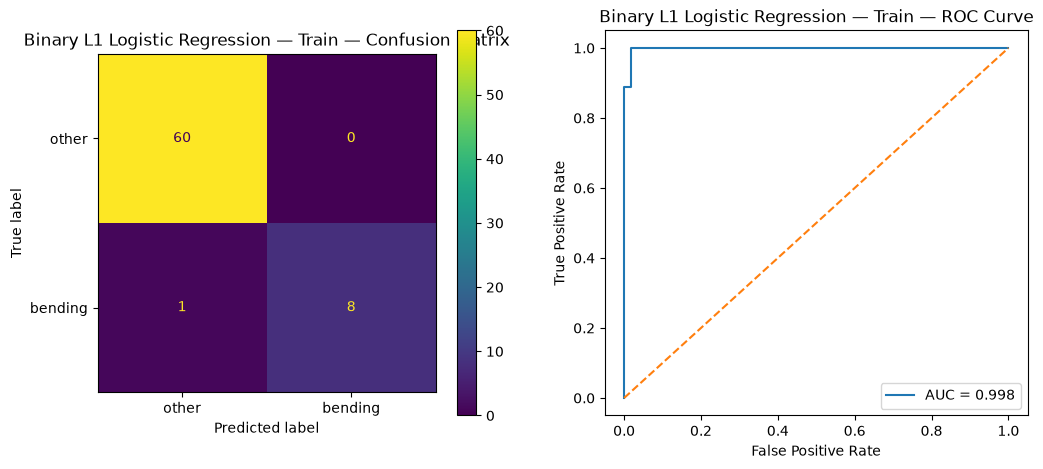

Binary L1 Logistic Regression — Train AUC: 0.9981481481481481


,parameter,coefficient,p_value,p_values_reliable
0,const,-63.038515,0.998553,False
1,max_1,-6.066828,0.999829,False
2,max_5,40.232470,0.998622,False
3,min_3,-16.666173,0.999511,False
4,min_5,47.545136,0.998955,False
5,std_6,4.294742,0.999797,False


In [23]:
fitted_model = fit_final_model(
    train_dfs, l=best_l, stats=stats, l1=True, lambda_=best_lambda
)

model_name = "Binary L1 Logistic Regression"

train_results = evaluate_final_model(
    fitted_model,
    train_dfs,
    model_name=f"{model_name} — Train",
)
parameter_table = model_parameters_and_pvalues(
    fitted_model,
    train_dfs,
)

print(f"{model_name} — Train AUC:", train_results["auc"])

parameter_table

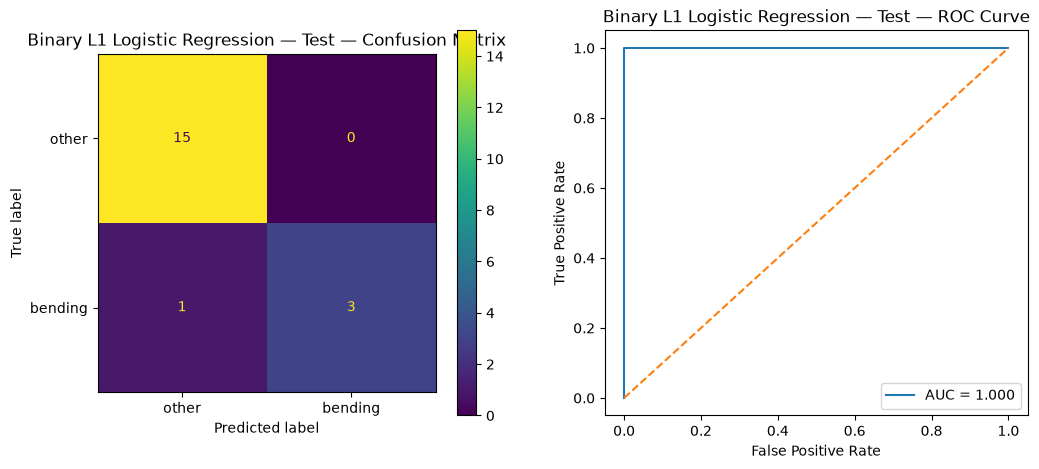

Binary L1 Logistic Regression — Test accuracy: 0.9473684210526315


In [24]:
test_predictions, test_accuracy = predict_final_model(
    fitted_model,
    test_dfs,
)

test_results = evaluate_final_model(
    fitted_model,
    test_dfs,
    model_name=f"{model_name} — Test",
)

print(f"{model_name} — Test accuracy:", test_accuracy)

#### ii)

The p-values in the L1 penalized regression are less reliable. This can also be seen with the coefficient sizes. However, the L1 model performed a bit better recall at 75% as opposed to 50%. It does seem like we don't have enough data to truly tell.

### c)

#### i)

In [25]:
def extract_features_multinomial(dfs, l=1):
    feature_df = extract_features(dfs, l=l).copy()
    feature_df["label"] = feature_df["action"]
    return feature_df


def candidate_feature_names_multinomial(l, stats):
    return [
        f"{stat}_{series}" if l == 1 else f"{stat}_{series}_{segment}"
        for stat in stats
        for series in range(1, 7)
        for segment in range(1, l + 1)
    ]


def prepare_xy_multinomial(dfs, l, stats):
    feature_df = extract_features_multinomial(dfs, l=l)
    feature_columns = candidate_feature_names_multinomial(l, stats)

    X = feature_df[feature_columns]
    y = feature_df["label"].to_numpy()

    return feature_df, X, y


def make_logistic_model_multinomial(lambda_, random_state=552):
    return LogisticRegression(
        solver="saga",
        l1_ratio=1,
        C=1 / lambda_,
        max_iter=10_000,
        random_state=random_state,
    )


def make_classifier_multinomial(model, lambda_=None, random_state=552):
    if model == "l1":
        return make_logistic_model_multinomial(lambda_, random_state)
    if model == "gaussian_nb":
        return GaussianNB()
    if model == "multinomial_nb":
        return MultinomialNB()


def tune_multinomial(
    dfs,
    l_values=range(1, 21),
    stats=("max", "min", "std"),
    model="l1",
    lambdas=(0.001, 0.01, 0.1, 1, 10),
    n_splits=5,
    scoring="accuracy",
    random_state=552,
):
    results = []
    scorer = get_scorer(scoring)

    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=random_state,
    )

    lambda_values = lambdas if model == "l1" else (None,)

    folds = None

    for l in tqdm(l_values, desc="Tuning l", unit="l"):
        _, X, y = prepare_xy_multinomial(dfs, l=l, stats=stats)

        if folds is None:
            folds = list(cv.split(X, y))

        fold_scores = {lambda_: np.empty(n_splits) for lambda_ in lambda_values}

        for fold_number, (train_idx, validation_idx) in enumerate(folds):
            X_train = X.iloc[train_idx].to_numpy()
            X_validation = X.iloc[validation_idx].to_numpy()
            y_train = y[train_idx]
            y_validation = y[validation_idx]

            if model == "l1":
                scaler = StandardScaler()
                X_train_model = scaler.fit_transform(X_train)
                X_validation_model = scaler.transform(X_validation)
            else:
                X_train_model = X_train
                X_validation_model = X_validation

            for lambda_ in lambda_values:
                classifier = make_classifier_multinomial(
                    model,
                    lambda_,
                    random_state,
                )
                classifier.fit(X_train_model, y_train)

                fold_scores[lambda_][fold_number] = scorer(
                    classifier,
                    X_validation_model,
                    y_validation,
                )

        for lambda_ in lambda_values:
            scores = fold_scores[lambda_]

            results.append(
                {
                    "l": l,
                    "model": model,
                    "lambda": lambda_,
                    "mean_cv_score": scores.mean(),
                    "std_cv_score": scores.std(),
                }
            )

    all_results = pd.DataFrame(results)

    best_by_l = (
        all_results.loc[all_results.groupby("l")["mean_cv_score"].idxmax()]
        .sort_values("l")
        .reset_index(drop=True)
    )

    return all_results, best_by_l


def fit_final_model_multinomial(
    dfs,
    l,
    model="l1",
    lambda_=None,
    stats=("max", "min", "std"),
    random_state=552,
):
    _, X_train, y_train = prepare_xy_multinomial(
        dfs,
        l=l,
        stats=stats,
    )

    feature_names = X_train.columns

    if model == "l1":
        scaler = StandardScaler()
        X_train_model = scaler.fit_transform(X_train.to_numpy())
    else:
        scaler = None
        X_train_model = X_train.to_numpy()

    classifier = make_classifier_multinomial(
        model,
        lambda_,
        random_state,
    )
    classifier.fit(X_train_model, y_train)

    if model == "l1":
        selected_mask = np.any(classifier.coef_ != 0, axis=0)
    else:
        selected_mask = np.ones(X_train.shape[1], dtype=bool)

    return {
        "l": l,
        "model": model,
        "lambda": lambda_,
        "stats": stats,
        "scaler": scaler,
        "selected_mask": selected_mask,
        "selected_features": feature_names[selected_mask].tolist(),
        "classifier": classifier,
    }


def get_selected_data_multinomial(fitted_model, dfs):
    feature_df, X, y = prepare_xy_multinomial(
        dfs,
        l=fitted_model["l"],
        stats=fitted_model["stats"],
    )

    if fitted_model["scaler"] is None:
        X_selected = X.to_numpy()
    else:
        X_selected = fitted_model["scaler"].transform(X.to_numpy())

    return feature_df, X_selected, y


def evaluate_final_model_multinomial(fitted_model, dfs, model_name=None):
    # https://scikit-learn.org/stable/modules/generated/sklearn.metrics.multilabel_confusion_matrix.html

    feature_df, X_selected, y = get_selected_data_multinomial(
        fitted_model,
        dfs,
    )

    classifier = fitted_model["classifier"]
    predictions = classifier.predict(X_selected)
    probabilities = classifier.predict_proba(X_selected)

    accuracy = (predictions == y).mean()
    labels = classifier.classes_
    cm = confusion_matrix(y, predictions, labels=labels)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels,
    ).plot(xticks_rotation=45)

    title_prefix = f"{model_name} — " if model_name else ""
    plt.title(f"{title_prefix}Multinomial Confusion Matrix — Accuracy: {accuracy:.3f}")
    plt.show()

    results = feature_df[["action", "dataset_id", "label"]].copy()

    results["prediction"] = predictions

    for class_number, activity in enumerate(labels):
        results[f"probability_{activity}"] = probabilities[:, class_number]

    return {
        "accuracy": accuracy,
        "confusion_matrix": cm,
        "labels": labels,
        "predictions": results,
    }


def plot_ovr_roc_multinomial(fitted_model, dfs, model_name=None):
    _, X_selected, y = get_selected_data_multinomial(
        fitted_model,
        dfs,
    )
    # https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html

    classifier = fitted_model["classifier"]
    labels = classifier.classes_
    probabilities = classifier.predict_proba(X_selected)
    y_binary = label_binarize(y, classes=labels)

    plt.figure(figsize=(9, 7))

    for class_number, activity in enumerate(labels):
        fpr, tpr, _ = roc_curve(
            y_binary[:, class_number],
            probabilities[:, class_number],
        )

        plt.plot(
            fpr,
            tpr,
            label=f"{activity} — AUC = {auc(fpr, tpr):.3f}",
        )

    macro_auc = roc_auc_score(
        y,
        probabilities,
        labels=labels,
        multi_class="ovr",
        average="macro",
    )

    plt.plot([0, 1], [0, 1], linestyle="--", color="black")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    title_prefix = f"{model_name} — " if model_name else ""
    plt.title(f"{title_prefix}One-vs-Rest ROC Curves — Macro AUC: {macro_auc:.3f}")
    plt.legend()
    plt.show()

    return macro_auc


def predict_final_model_multinomial(fitted_model, dfs, model_name=None):
    results = evaluate_final_model_multinomial(
        fitted_model,
        dfs,
        model_name=model_name,
    )

    return results["predictions"], results["accuracy"]

In [26]:
stats = ("max", "min", "std")
lambdas = tuple(10.0**exponent for exponent in range(-6, 7))

all_cv_results, best_by_l = tune_multinomial(
    train_dfs,
    stats=stats,
    lambdas=lambdas,
)

best_row = best_by_l.sort_values(
    ["mean_cv_score", "l", "lambda"],
    ascending=[False, True, True],
).iloc[0]

best_l = int(best_row["l"])
best_lambda = best_row["lambda"]

print(
    f"Multinomial L1 Logistic Regression — Best (l, lambda) = ({best_l}, {best_lambda})"
)

Tuning l:   0%|          | 0/20 [00:00<?, ?l/s]/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-4/.venv/lib/python3.12/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
Tuning l: 100%|██████████| 20/20 [06:15<00:00, 18.79s/l]

Multinomial L1 Logistic Regression — Best (l, lambda) = (3, 1e-06)


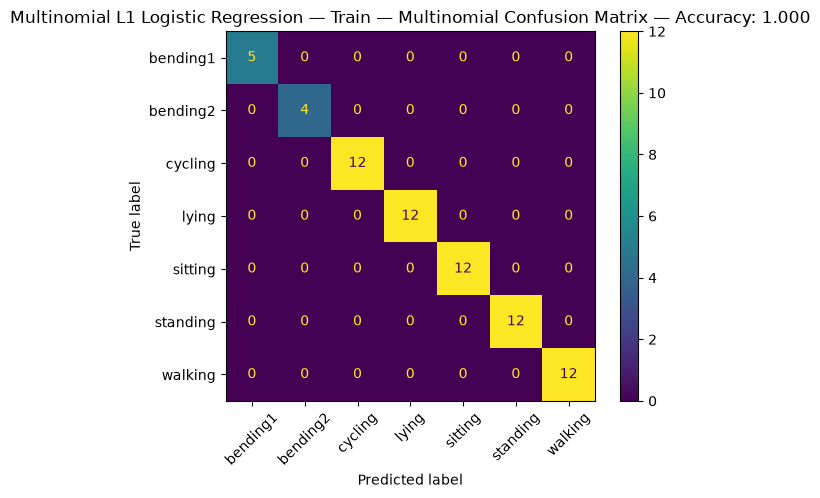

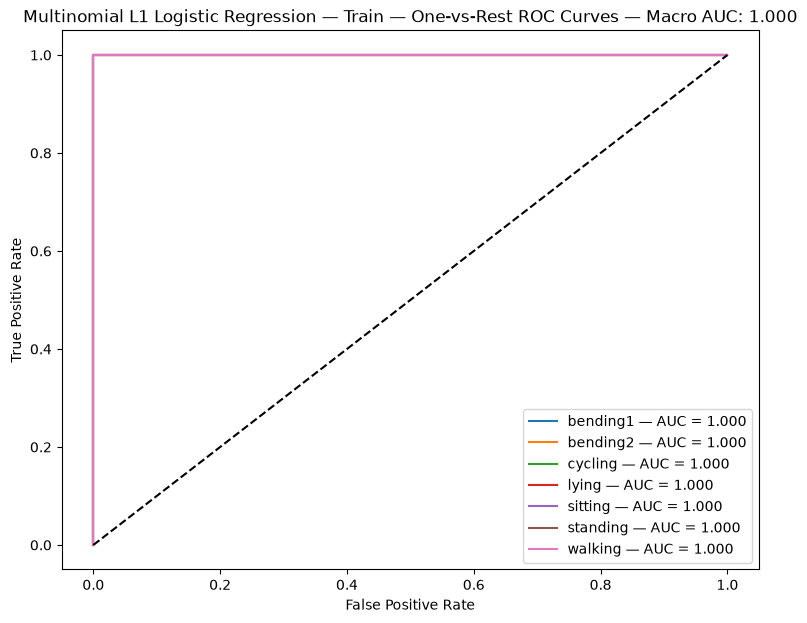

Multinomial L1 Logistic Regression — Train accuracy: 1.0
Multinomial L1 Logistic Regression — Train macro OVR AUC: 1.0


In [27]:
best_row = best_by_l.sort_values(
    ["mean_cv_score", "l", "lambda"],
    ascending=[False, True, True],
).iloc[0]

fitted_model_multinomial = fit_final_model_multinomial(
    train_dfs,
    l=int(best_row["l"]),
    stats=stats,
    lambda_=best_row["lambda"],
)

model_name = "Multinomial L1 Logistic Regression"

train_results = evaluate_final_model_multinomial(
    fitted_model_multinomial,
    train_dfs,
    model_name=f"{model_name} — Train",
)

macro_auc = plot_ovr_roc_multinomial(
    fitted_model_multinomial,
    train_dfs,
    model_name=f"{model_name} — Train",
)

print(f"{model_name} — Train accuracy:", train_results["accuracy"])
print(f"{model_name} — Train macro OVR AUC:", macro_auc)

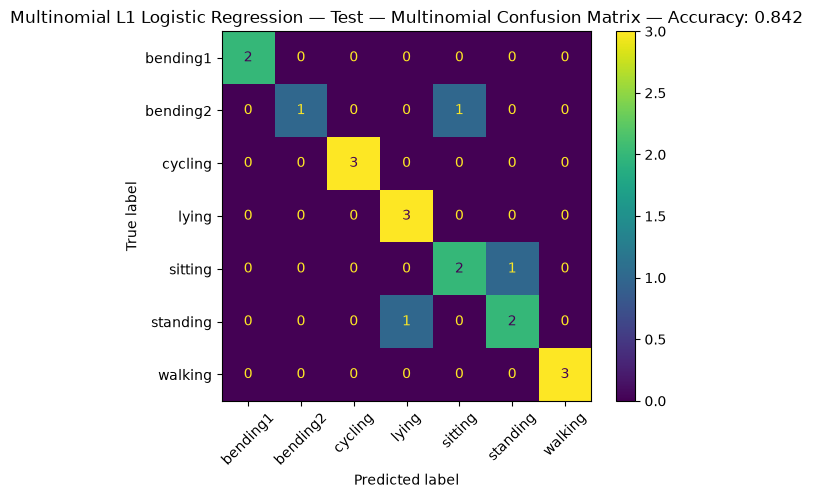

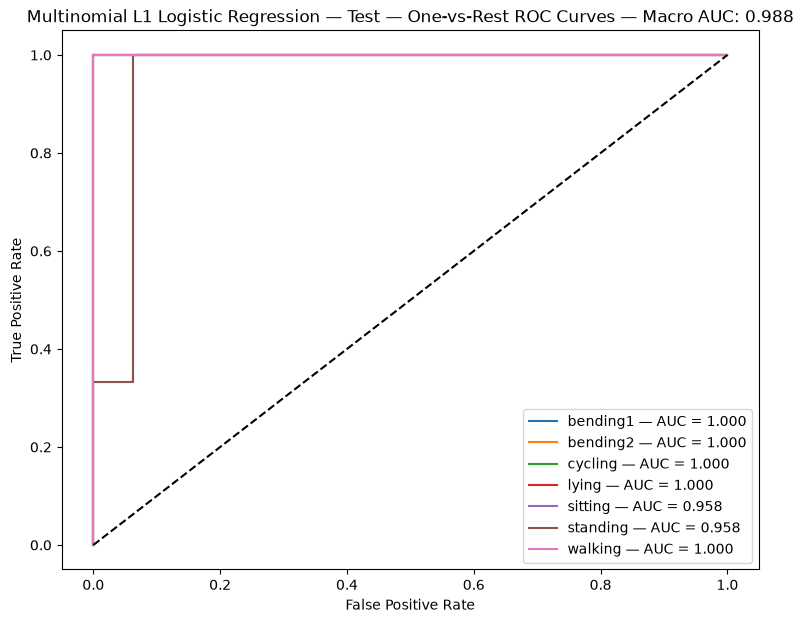

Multinomial L1 Logistic Regression — Test accuracy: 0.8421052631578947
Multinomial L1 Logistic Regression — Test macro OVR AUC: 0.988095238095238


In [28]:
test_results = evaluate_final_model_multinomial(
    fitted_model_multinomial,
    test_dfs,
    model_name=f"{model_name} — Test",
)

test_predictions = test_results["predictions"]
test_accuracy = test_results["accuracy"]

macro_auc = plot_ovr_roc_multinomial(
    fitted_model_multinomial,
    test_dfs,
    model_name=f"{model_name} — Test",
)

print(f"{model_name} — Test accuracy:", test_accuracy)
print(f"{model_name} — Test macro OVR AUC:", macro_auc)

#### ii)

In [29]:
stats = ("max", "min", "std")

all_cv_results, best_by_l = tune_multinomial(
    train_dfs, stats=stats, model="gaussian_nb"
)

best_row = best_by_l.sort_values(
    ["mean_cv_score", "l"],
    ascending=[False, True],
).iloc[0]

best_l = int(best_row["l"])

print(f"Gaussian Naive Bayes — Best (l) = ({best_l})")

Tuning l:   0%|          | 0/20 [00:00<?, ?l/s]/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-4/.venv/lib/python3.12/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
Tuning l: 100%|██████████| 20/20 [00:18<00:00,  1.08l/s]

Gaussian Naive Bayes — Best (l) = (2)


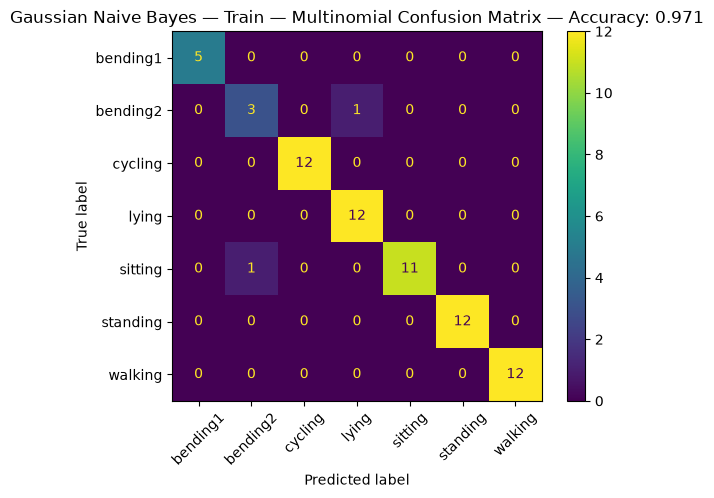

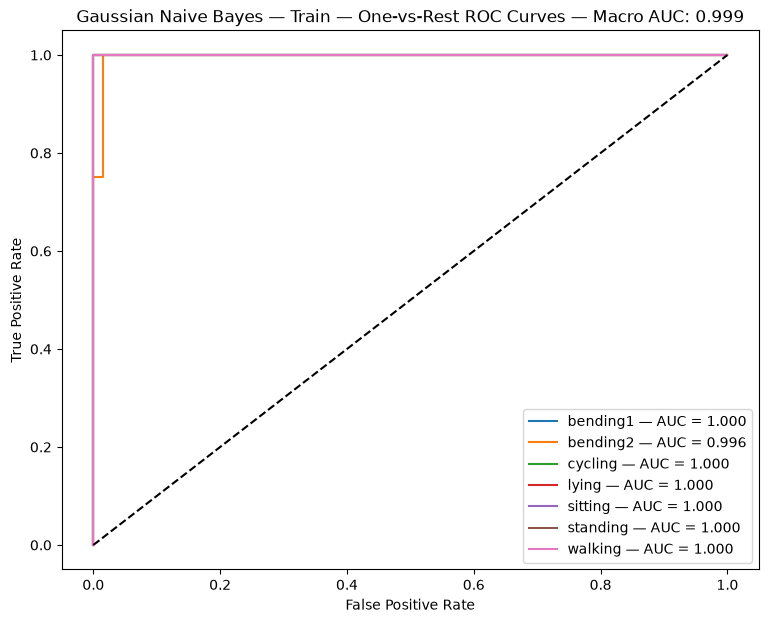

Gaussian Naive Bayes — Train accuracy: 0.9710144927536232
Gaussian Naive Bayes — Train macro OVR AUC: 0.9994505494505495


In [30]:
fitted_model_multinomial = fit_final_model_multinomial(
    train_dfs, l=int(best_row["l"]), stats=stats, model="gaussian_nb"
)

model_name = "Gaussian Naive Bayes"

train_results = evaluate_final_model_multinomial(
    fitted_model_multinomial,
    train_dfs,
    model_name=f"{model_name} — Train",
)

macro_auc = plot_ovr_roc_multinomial(
    fitted_model_multinomial,
    train_dfs,
    model_name=f"{model_name} — Train",
)

print(f"{model_name} — Train accuracy:", train_results["accuracy"])
print(f"{model_name} — Train macro OVR AUC:", macro_auc)

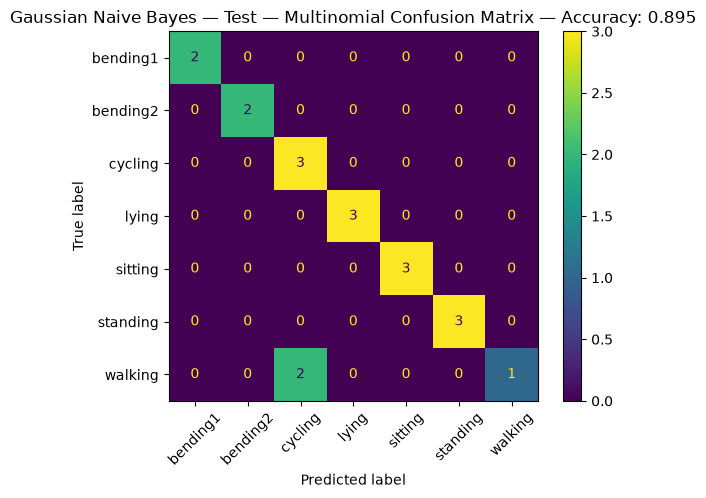

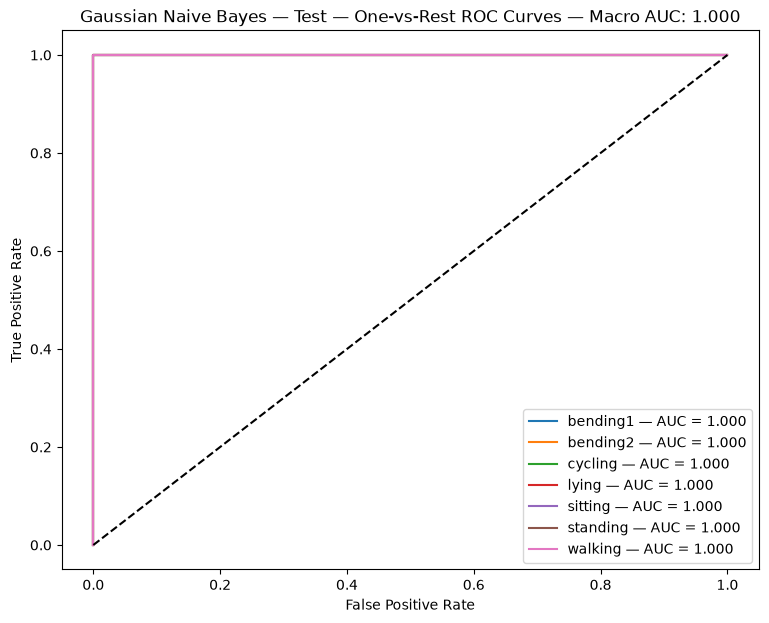

Gaussian Naive Bayes — Test accuracy: 0.8947368421052632
Gaussian Naive Bayes — Test macro OVR AUC: 1.0


In [31]:
test_results = evaluate_final_model_multinomial(
    fitted_model_multinomial,
    test_dfs,
    model_name=f"{model_name} — Test",
)

test_predictions = test_results["predictions"]
test_accuracy = test_results["accuracy"]

macro_auc = plot_ovr_roc_multinomial(
    fitted_model_multinomial,
    test_dfs,
    model_name=f"{model_name} — Test",
)

print(f"{model_name} — Test accuracy:", test_accuracy)
print(f"{model_name} — Test macro OVR AUC:", macro_auc)

In [32]:
stats = ("max", "min", "std")

all_cv_results, best_by_l = tune_multinomial(
    train_dfs, stats=stats, model="multinomial_nb"
)

best_row = best_by_l.sort_values(
    ["mean_cv_score", "l"],
    ascending=[False, True],
).iloc[0]

best_l = int(best_row["l"])

print(f"Multinomial Naive Bayes — Best (l) = ({best_l})")

Tuning l:   0%|          | 0/20 [00:00<?, ?l/s]/Users/maxwellbederman/Desktop/School/USC/Fall 2026/DSCI 552/dsci-552-homework-4/.venv/lib/python3.12/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
Tuning l: 100%|██████████| 20/20 [00:18<00:00,  1.09l/s]

Multinomial Naive Bayes — Best (l) = (11)


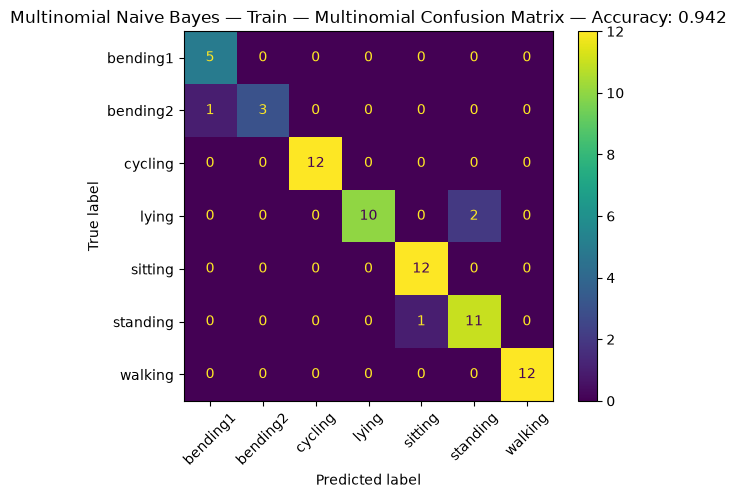

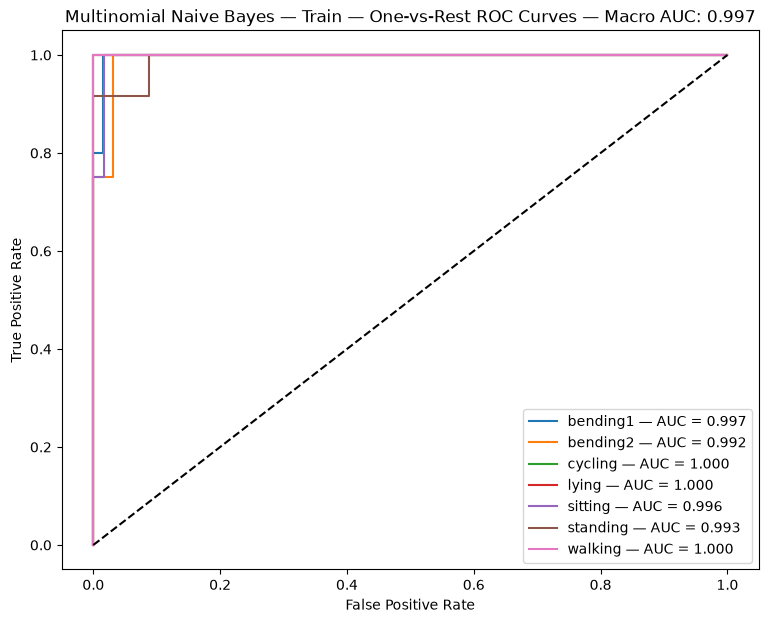

Multinomial Naive Bayes — Train accuracy: 0.9420289855072463
Multinomial Naive Bayes — Train macro OVR AUC: 0.9967838265535633


In [33]:
fitted_model_multinomial = fit_final_model_multinomial(
    train_dfs, l=int(best_row["l"]), stats=stats, model="multinomial_nb"
)

model_name = "Multinomial Naive Bayes"

train_results = evaluate_final_model_multinomial(
    fitted_model_multinomial,
    train_dfs,
    model_name=f"{model_name} — Train",
)

macro_auc = plot_ovr_roc_multinomial(
    fitted_model_multinomial,
    train_dfs,
    model_name=f"{model_name} — Train",
)

print(f"{model_name} — Train accuracy:", train_results["accuracy"])
print(f"{model_name} — Train macro OVR AUC:", macro_auc)

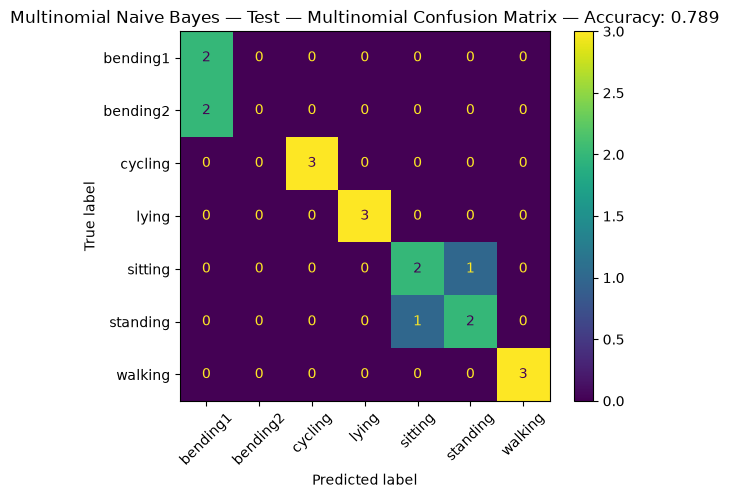

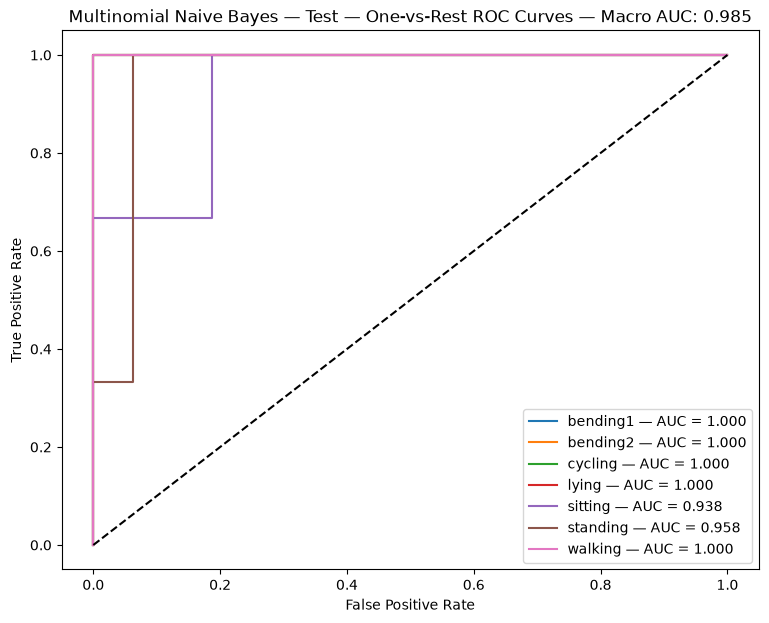

Multinomial Naive Bayes — Test accuracy: 0.7894736842105263
Multinomial Naive Bayes — Test macro OVR AUC: 0.9851190476190476


In [34]:
test_results = evaluate_final_model_multinomial(
    fitted_model_multinomial,
    test_dfs,
    model_name=f"{model_name} — Test",
)

test_predictions = test_results["predictions"]
test_accuracy = test_results["accuracy"]

macro_auc = plot_ovr_roc_multinomial(
    fitted_model_multinomial,
    test_dfs,
    model_name=f"{model_name} — Test",
)

print(f"{model_name} — Test accuracy:", test_accuracy)
print(f"{model_name} — Test macro OVR AUC:", macro_auc)

#### iii)

The gaussian naive bayes seems to do the best out of the three on the test set. It also takes significantly less time to train so that is another advantage as well. The L1 model has higher train accuracy so it seems like its overfitting and the parameters are actually more independent than the small data source we have suggests.

## 3)

$$X | Y = k \sim N(\mu_k, \sigma_k^2)$$
$$ f_k(y | x) \propto \pi_k \frac{1}{\sqrt{2\pi\sigma^2_k}}\exp{\frac{-(x - \mu_k)^2}{2\sigma_k^2}}$$
$$ l_k(y |x) = \log{\pi_k} - \frac{1}{2}\log{\sigma^2_k} - \frac{(x - \mu_k)^2}{2\sigma_k^2}$$

This $l_k$ is what we attempt to arg max to find our class prediction k, which is a quadratic function w.r.t x.

## 4)

In [35]:
def normpdf(x, mean, std):
    return 1 / (std * np.sqrt(2 * np.pi)) * np.exp(-0.5 * ((x - mean) / std) ** 2)

In [36]:
mu_yes = 10
mu_no = 0
var_yes = 36
var_no = 36

p_yes = 0.8

x = 4

prob = (p_yes * normpdf(x, mu_yes, np.sqrt(var_yes))) / (
    p_yes * normpdf(x, mu_yes, np.sqrt(var_yes))
    + (1 - p_yes) * normpdf(x, mu_no, np.sqrt(var_no))
)
print(f"Probability of Yes for X = 4 is: {prob}")

Probability of Yes for X = 4 is: 0.7518524532975261
